In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [2]:
file_path = "../data/processed/delhi_petrol_processed.csv"

df = pd.read_csv(file_path)

df.head()

,date,city,petrol_price,previous_petrol_price,petrol_price_change,petrol_return,log_return,petrol_ma_7,petrol_ma_30,volatility_7d,volatility_30d,momentum_7d,momentum_30d,price_vs_ma_7,price_vs_ma_30,target_next_day_petrol_price,target_next_day_change
0,2017-07-16,Delhi,64.11,64.03,0.08,0.001249,0.001249,63.947143,63.807000,0.020042,0.036842,0.007227,-0.020922,0.002547,0.004749,64.15,0.04
1,2017-07-17,Delhi,64.15,64.11,0.04,0.000624,0.000624,63.992857,63.771000,0.015625,0.035810,0.005013,-0.016557,0.002456,0.005943,64.21,0.06
2,2017-07-18,Delhi,64.21,64.15,0.06,0.000935,0.000935,64.032857,63.747667,0.014608,0.033563,0.004380,-0.010784,0.002766,0.007253,64.21,0.00
3,2017-07-19,Delhi,64.21,64.21,0.00,0.000000,0.000000,64.072857,63.733000,0.014608,0.031734,0.004380,-0.006806,0.002140,0.007484,64.25,0.04
4,2017-07-20,Delhi,64.25,64.21,0.04,0.000623,0.000623,64.121429,63.723000,0.013086,0.031572,0.005320,-0.004648,0.002005,0.008270,64.28,0.03


In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Info:")
df.info()

Shape: (3341, 17)

Columns:
['date', 'city', 'petrol_price', 'previous_petrol_price', 'petrol_price_change', 'petrol_return', 'log_return', 'petrol_ma_7', 'petrol_ma_30', 'volatility_7d', 'volatility_30d', 'momentum_7d', 'momentum_30d', 'price_vs_ma_7', 'price_vs_ma_30', 'target_next_day_petrol_price', 'target_next_day_change']

Data Types:
date                             object
city                             object
petrol_price                    float64
previous_petrol_price           float64
petrol_price_change             float64
petrol_return                   float64
log_return                      float64
petrol_ma_7                     float64
petrol_ma_30                    float64
volatility_7d                   float64
volatility_30d                  float64
momentum_7d                     float64
momentum_30d                    float64
price_vs_ma_7                   float64
price_vs_ma_30                  float64
target_next_day_petrol_price    float64
target_next_day_c

In [4]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())

Start Date: 2017-07-16 00:00:00
End Date: 2026-09-07 00:00:00


In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
date                            0
city                            0
petrol_price                    0
previous_petrol_price           0
petrol_price_change             0
petrol_return                   0
log_return                      0
petrol_ma_7                     0
petrol_ma_30                    0
volatility_7d                   0
volatility_30d                  0
momentum_7d                     0
momentum_30d                    0
price_vs_ma_7                   0
price_vs_ma_30                  0
target_next_day_petrol_price    0
target_next_day_change          0
dtype: int64

Total Missing Values: 0


In [6]:
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Dates:", df["date"].duplicated().sum())

Duplicate Rows: 0
Duplicate Dates: 0


In [7]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,3341,2022-02-10 00:00:00,2017-07-16 00:00:00,2019-10-29 00:00:00,2022-02-10 00:00:00,2024-05-25 00:00:00,2026-09-07 00:00:00,NaN
petrol_price,3341.0,87.924502,64.11,74.88,94.77,96.72,110.04,11.452708
previous_petrol_price,3341.0,87.913101,64.03,74.86,94.77,96.72,110.04,11.45753
petrol_price_change,3341.0,0.011401,-8.69,0.0,0.0,0.0,3.0,0.28195
petrol_return,3341.0,0.000144,-0.08244,0.0,0.0,0.0,0.034747,0.002912
log_return,3341.0,0.00014,-0.086037,0.0,0.0,0.0,0.034157,0.002981
petrol_ma_7,3341.0,87.890219,63.947143,74.865714,94.77,96.72,109.29,11.462405
petrol_ma_30,3341.0,87.757444,63.709333,74.796333,94.77,96.72,106.428333,11.491153
volatility_7d,3341.0,0.011838,0.0,0.0,0.0,0.012379,0.516224,0.042873
volatility_30d,3341.0,0.020172,0.0,0.0,0.005961,0.021959,0.293649,0.041092


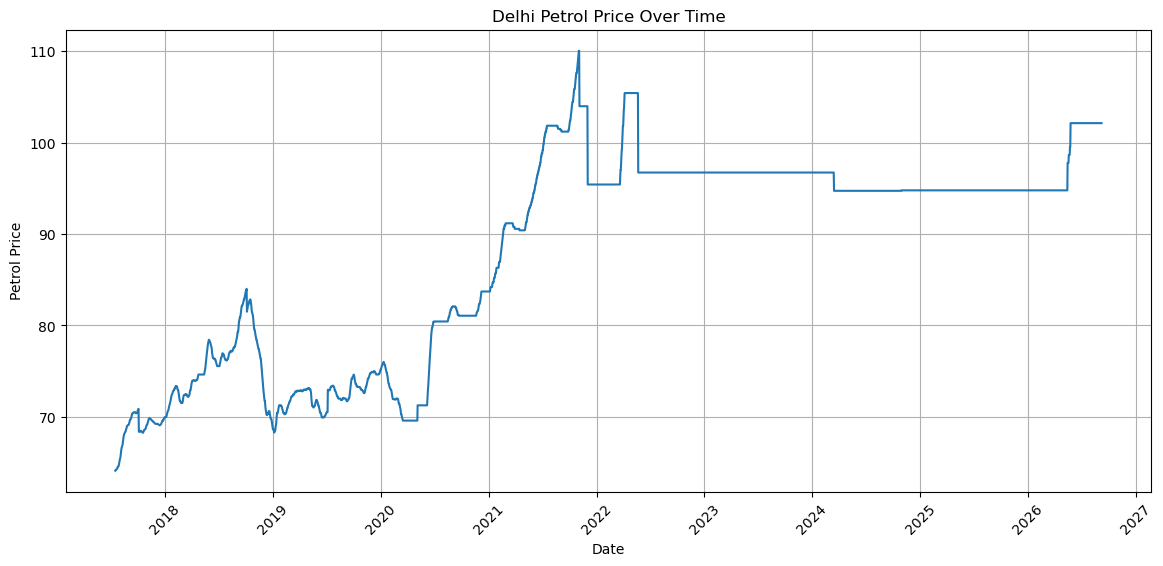

In [8]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["petrol_price"]
)

plt.title("Delhi Petrol Price Over Time")
plt.xlabel("Date")
plt.ylabel("Petrol Price")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

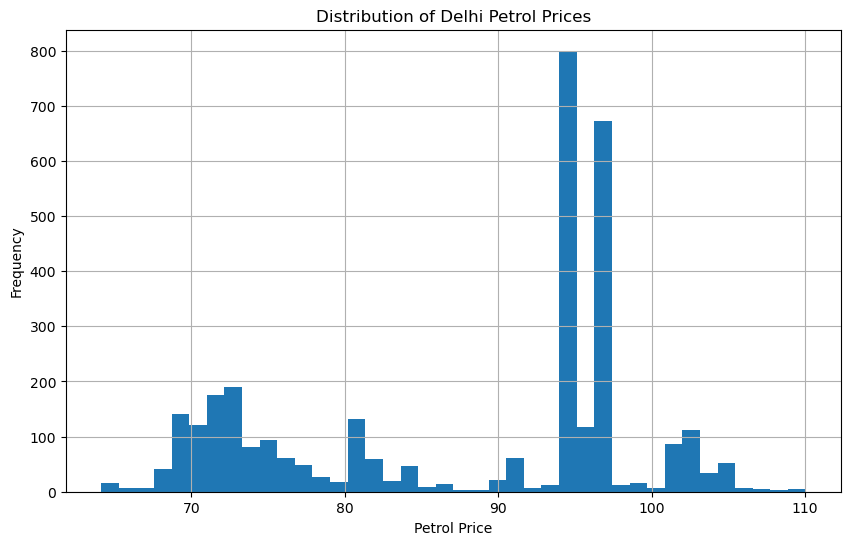

In [9]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["petrol_price"].dropna(),
    bins=40
)

plt.title("Distribution of Delhi Petrol Prices")
plt.xlabel("Petrol Price")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

In [11]:
print("Available columns:")
print(df.columns.tolist())

Available columns:
['date', 'city', 'petrol_price', 'previous_petrol_price', 'petrol_price_change', 'petrol_return', 'log_return', 'petrol_ma_7', 'petrol_ma_30', 'volatility_7d', 'volatility_30d', 'momentum_7d', 'momentum_30d', 'price_vs_ma_7', 'price_vs_ma_30', 'target_next_day_petrol_price', 'target_next_day_change']


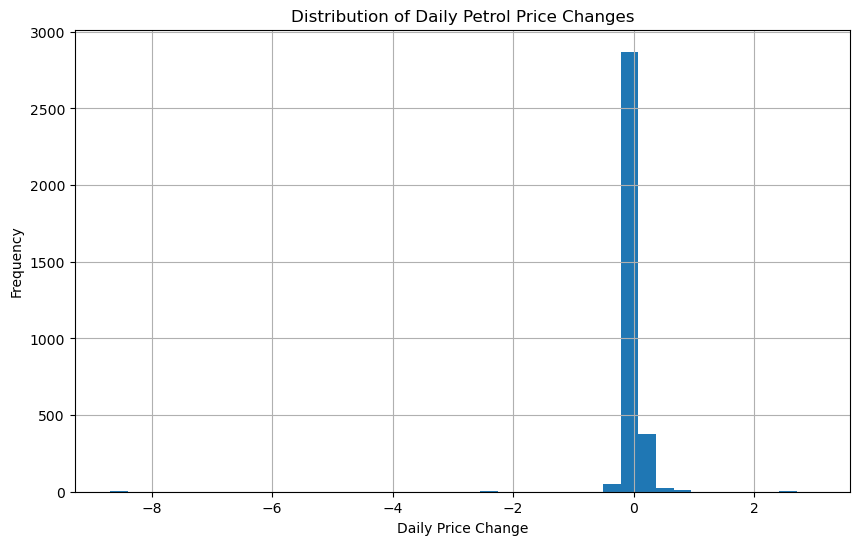

In [12]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["petrol_price_change"].dropna(),
    bins=40
)

plt.title("Distribution of Daily Petrol Price Changes")
plt.xlabel("Daily Price Change")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

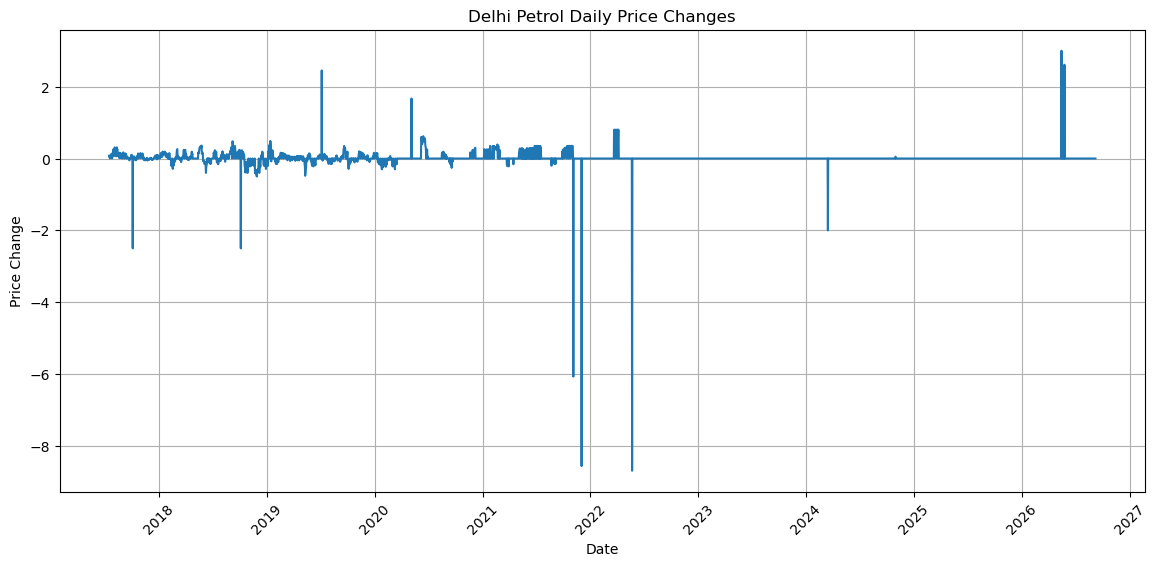

In [14]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["petrol_price_change"]
)

plt.title("Delhi Petrol Daily Price Changes")
plt.xlabel("Date")
plt.ylabel("Price Change")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

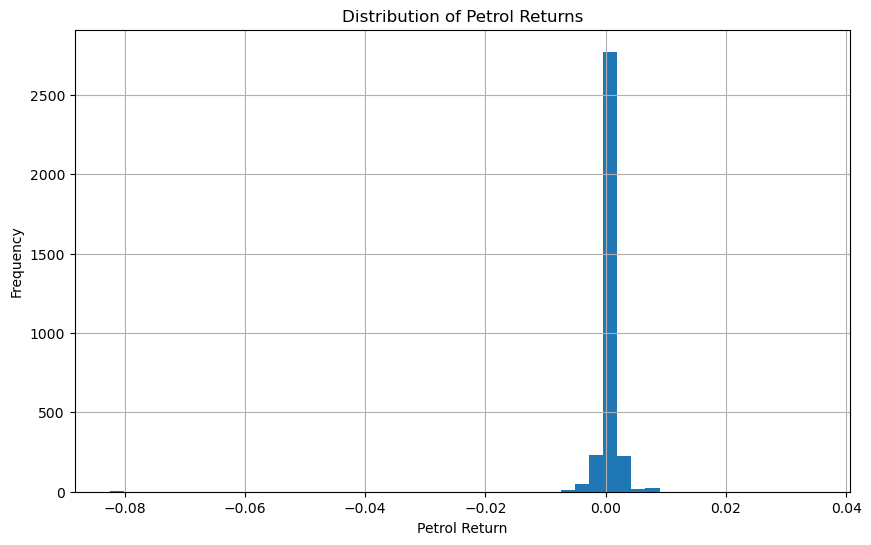

In [15]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["petrol_return"].dropna(),
    bins=50
)

plt.title("Distribution of Petrol Returns")
plt.xlabel("Petrol Return")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

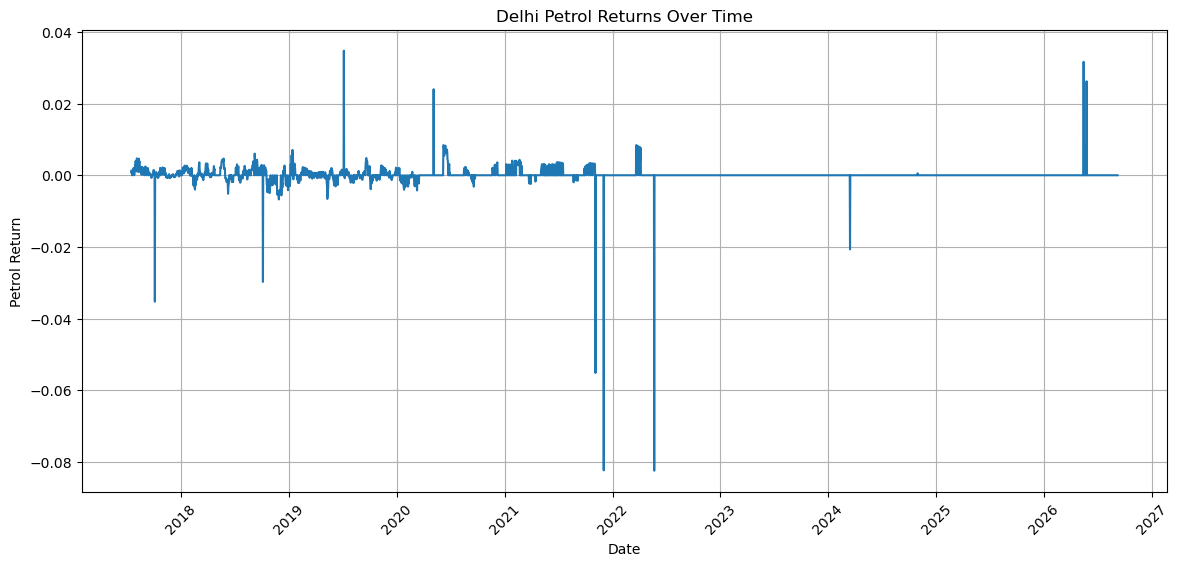

In [16]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["petrol_return"]
)

plt.title("Delhi Petrol Returns Over Time")
plt.xlabel("Date")
plt.ylabel("Petrol Return")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [17]:
print("Mean Return:", df["petrol_return"].mean())
print("Median Return:", df["petrol_return"].median())
print("Standard Deviation:", df["petrol_return"].std())
print("Minimum Return:", df["petrol_return"].min())
print("Maximum Return:", df["petrol_return"].max())

Mean Return: 0.00014409911678609476
Median Return: 0.0
Standard Deviation: 0.0029119096864022565
Minimum Return: -0.0824399962052936
Maximum Return: 0.0347468444192311


In [18]:
volatility_columns = [
    col for col in df.columns
    if "volatility" in col.lower()
]

print("Volatility Columns:")
print(volatility_columns)

Volatility Columns:
['volatility_7d', 'volatility_30d']


In [19]:
if "volatility_30d" in df.columns:
    volatility_col = "volatility_30d"
elif "volatility_7d" in df.columns:
    volatility_col = "volatility_7d"
else:
    volatility_col = volatility_columns[-1]

print("Selected Volatility Column:", volatility_col)

Selected Volatility Column: volatility_30d


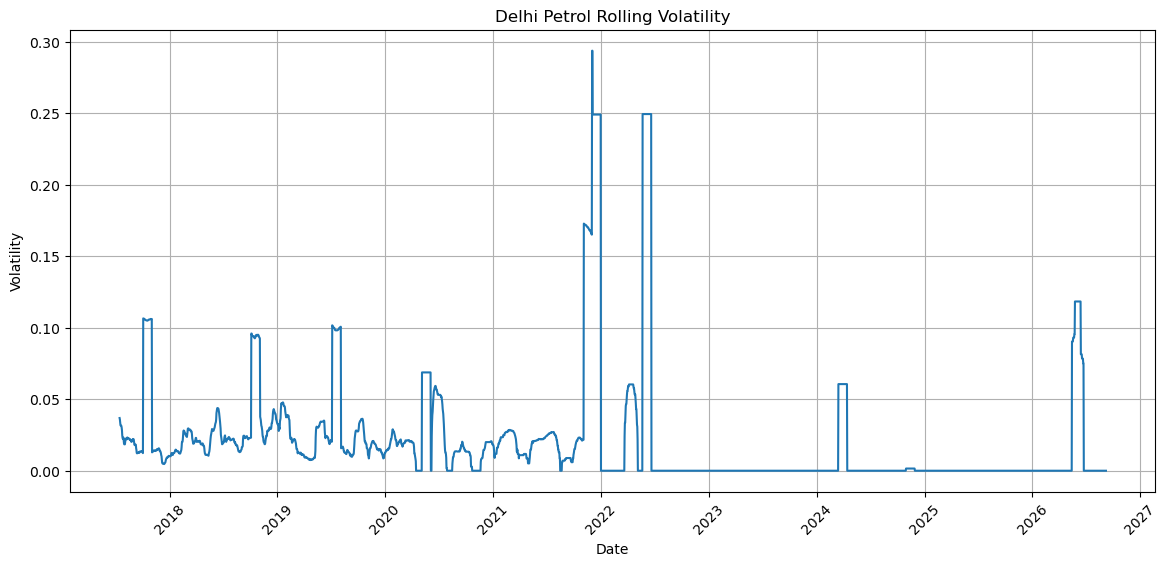

In [20]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df[volatility_col]
)

plt.title("Delhi Petrol Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [21]:
df[volatility_col].describe()

count    3341.000000
mean        0.020172
std         0.041092
min         0.000000
25%         0.000000
50%         0.005961
75%         0.021959
max         0.293649
Name: volatility_30d, dtype: float64

In [22]:
highest_volatility = (
    df[["date", volatility_col]]
    .sort_values(
        by=volatility_col,
        ascending=False
    )
    .head(10)
)

highest_volatility

,date,volatility_30d
1601,2021-12-03,0.293649
1600,2021-12-02,0.293649
1794,2022-06-14,0.249360
1778,2022-05-29,0.249360
1795,2022-06-15,0.249360
1800,2022-06-20,0.249360
1799,2022-06-19,0.249360
1798,2022-06-18,0.249360
1797,2022-06-17,0.249360
1796,2022-06-16,0.249360


In [23]:
ma_columns = [
    col for col in df.columns
    if "petrol_ma" in col.lower()
]

print("Moving Average Columns:")
print(ma_columns)

Moving Average Columns:
['petrol_ma_7', 'petrol_ma_30']


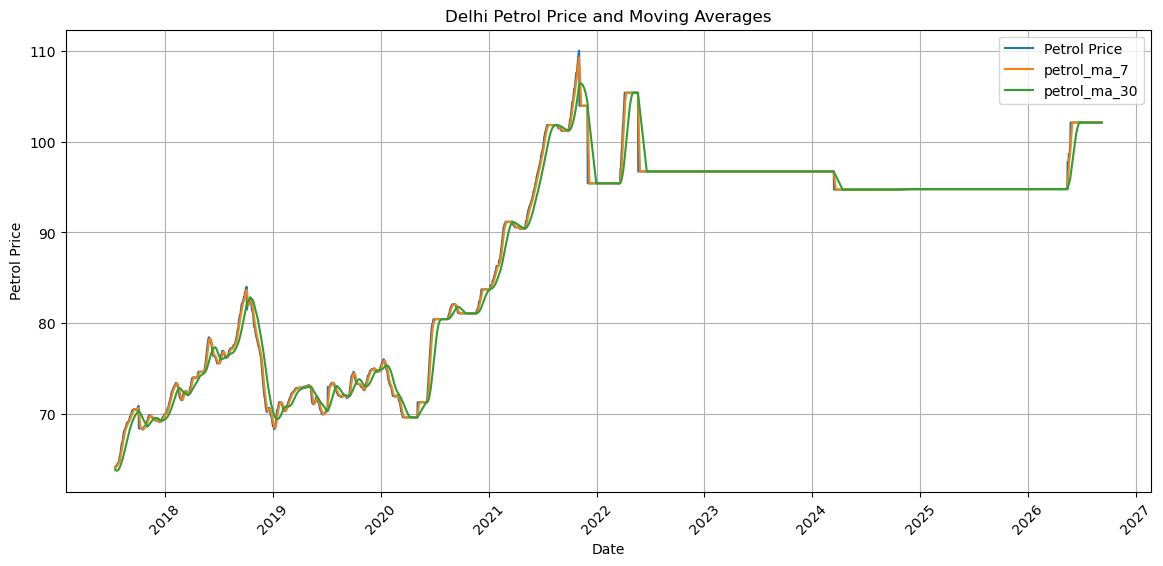

In [24]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["petrol_price"],
    label="Petrol Price"
)

for col in ma_columns:
    plt.plot(
        df["date"],
        df[col],
        label=col
    )

plt.title("Delhi Petrol Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Petrol Price")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [25]:
momentum_columns = [
    col for col in df.columns
    if "momentum" in col.lower()
]

print("Momentum Columns:")
print(momentum_columns)

Momentum Columns:
['momentum_7d', 'momentum_30d']


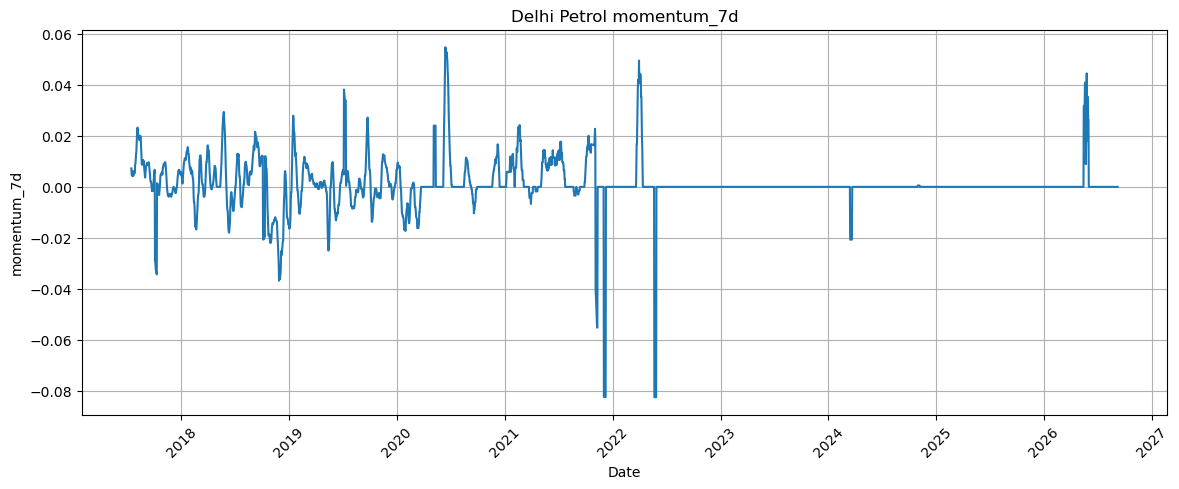

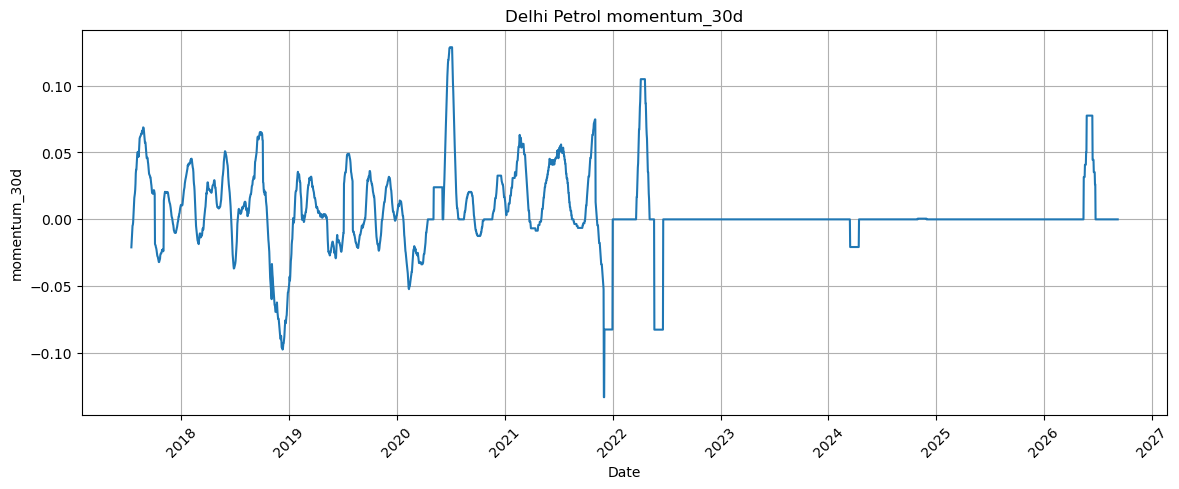

In [26]:
for col in momentum_columns:

    plt.figure(figsize=(14, 5))

    plt.plot(
        df["date"],
        df[col]
    )

    plt.title(f"Delhi Petrol {col}")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.grid(True)

    plt.show()

In [27]:
price_ma_columns = [
    col for col in df.columns
    if "price_vs_ma" in col.lower()
]

print("Price vs MA Columns:")
print(price_ma_columns)

Price vs MA Columns:
['price_vs_ma_7', 'price_vs_ma_30']


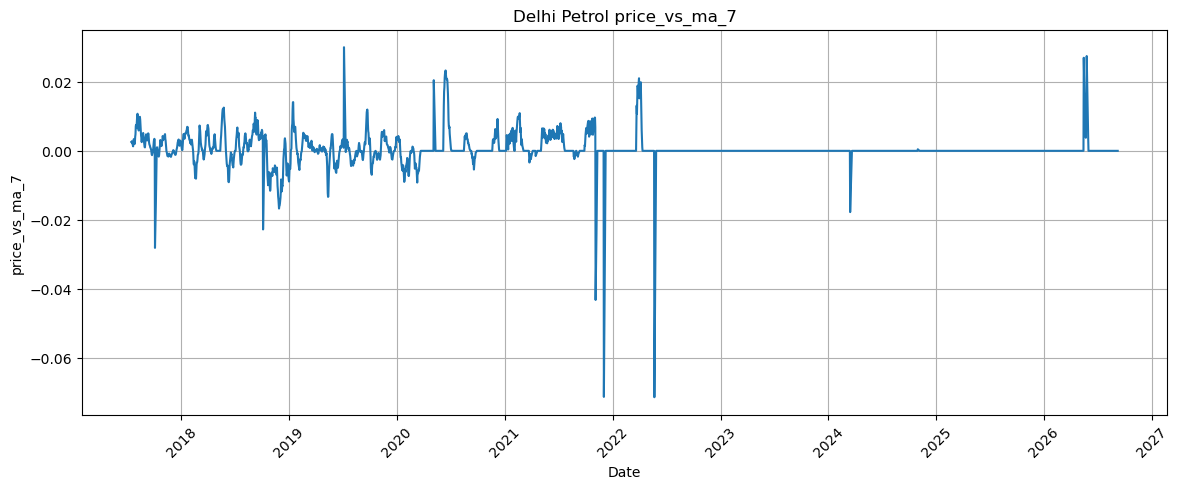

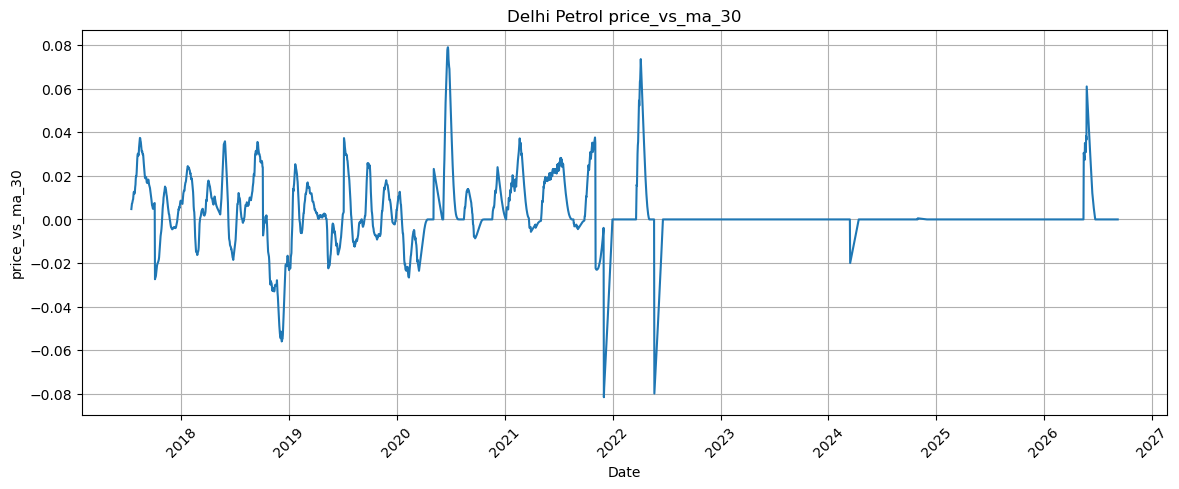

In [28]:
for col in price_ma_columns:

    plt.figure(figsize=(14, 5))

    plt.plot(
        df["date"],
        df[col]
    )

    plt.title(f"Delhi Petrol {col}")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.grid(True)

    plt.show()

In [29]:
target_col = "target_next_day_petrol_price"

print("Target Column:", target_col)

print("\nTarget Statistics:")
print(df[target_col].describe())

Target Column: target_next_day_petrol_price

Target Statistics:
count    3341.000000
mean       87.935878
std        11.447922
min        64.150000
25%        74.890000
50%        94.770000
75%        96.720000
max       110.040000
Name: target_next_day_petrol_price, dtype: float64


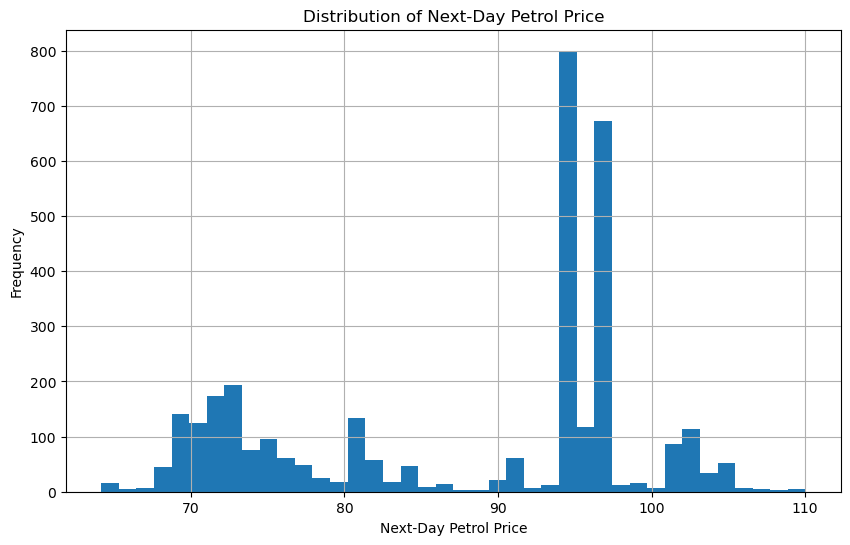

In [30]:
plt.figure(figsize=(10, 6))

plt.hist(
    df[target_col].dropna(),
    bins=40
)

plt.title("Distribution of Next-Day Petrol Price")
plt.xlabel("Next-Day Petrol Price")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

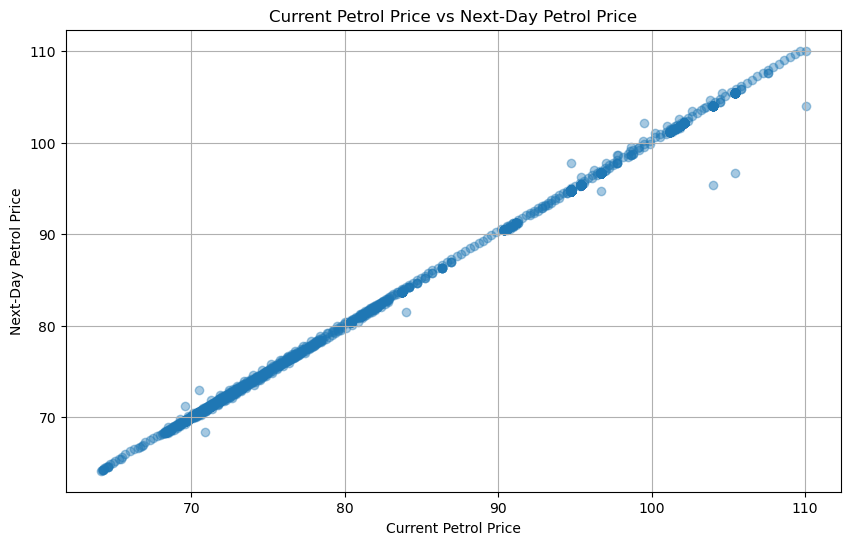

In [31]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["petrol_price"],
    df[target_col],
    alpha=0.4
)

plt.title("Current Petrol Price vs Next-Day Petrol Price")
plt.xlabel("Current Petrol Price")
plt.ylabel("Next-Day Petrol Price")
plt.grid(True)

plt.show()

In [32]:
corr = df.corr(numeric_only=True)

target_correlations = (
    corr[target_col]
    .sort_values(ascending=False)
)

target_correlations

target_next_day_petrol_price    1.000000
petrol_price                    0.999697
previous_petrol_price           0.999334
petrol_ma_7                     0.998785
petrol_ma_30                    0.992887
momentum_30d                    0.022615
price_vs_ma_30                  0.006939
petrol_price_change            -0.002350
target_next_day_change         -0.004663
momentum_7d                    -0.009573
petrol_return                  -0.010762
log_return                     -0.010947
price_vs_ma_7                  -0.013300
volatility_7d                  -0.064301
volatility_30d                 -0.083404
Name: target_next_day_petrol_price, dtype: float64

In [33]:
strongest_features = (
    target_correlations
    .drop(target_col)
    .sort_values(
        key=abs,
        ascending=False
    )
)

print("Strongest Feature Correlations:")
print(strongest_features.head(15))

Strongest Feature Correlations:
petrol_price              0.999697
previous_petrol_price     0.999334
petrol_ma_7               0.998785
petrol_ma_30              0.992887
volatility_30d           -0.083404
volatility_7d            -0.064301
momentum_30d              0.022615
price_vs_ma_7            -0.013300
log_return               -0.010947
petrol_return            -0.010762
momentum_7d              -0.009573
price_vs_ma_30            0.006939
target_next_day_change   -0.004663
petrol_price_change      -0.002350
Name: target_next_day_petrol_price, dtype: float64


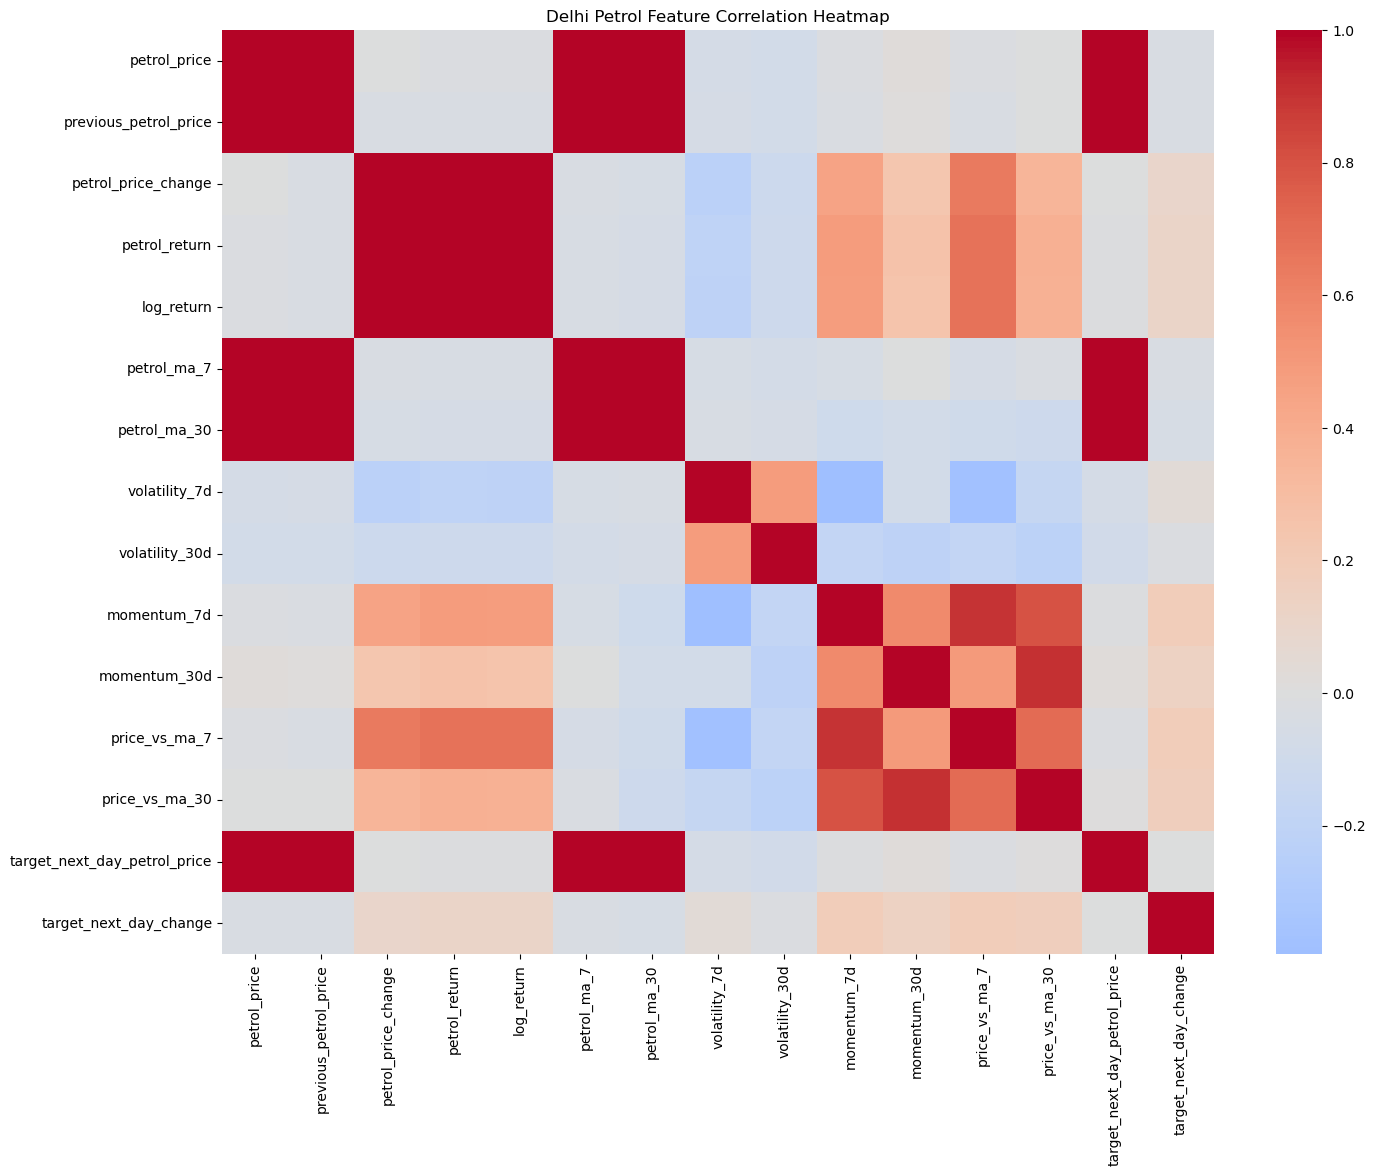

In [34]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)

plt.title("Delhi Petrol Feature Correlation Heatmap")

plt.show()

In [36]:
extreme_changes = (
    df[
        [
            "date",
            "petrol_price",
            "petrol_price_change",
            "petrol_return"
        ]
    ]
    .sort_values(
        by="petrol_return",
        key=abs,
        ascending=False
    )
    .head(15)
)

extreme_changes

,date,petrol_price,petrol_price_change,petrol_return
1771,2022-05-22,96.72,-8.69,-0.082440
1600,2021-12-02,95.41,-8.56,-0.082331
1572,2021-11-04,103.97,-6.07,-0.055162
80,2017-10-04,68.38,-2.50,-0.035271
720,2019-07-06,72.96,2.45,0.034747
3225,2026-05-15,97.77,3.00,0.031656
446,2018-10-05,81.50,-2.50,-0.029762
3235,2026-05-25,102.12,2.61,0.026229
1024,2020-05-05,71.26,1.67,0.023998
2434,2024-03-15,94.72,-2.00,-0.020678


In [37]:
print("Lowest Petrol Price:")
print(
    df.loc[
        df["petrol_price"].idxmin(),
        ["date", "petrol_price"]
    ]
)

print("\nHighest Petrol Price:")
print(
    df.loc[
        df["petrol_price"].idxmax(),
        ["date", "petrol_price"]
    ]
)

Lowest Petrol Price:
date            2017-07-16 00:00:00
petrol_price                  64.11
Name: 0, dtype: object

Highest Petrol Price:
date            2021-11-02 00:00:00
petrol_price                 110.04
Name: 1570, dtype: object


In [38]:
print("FINAL DATA QUALITY CHECK")
print("------------------------")

print("Rows:", len(df))
print("Columns:", len(df.columns))

print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Dates:", df["date"].duplicated().sum())

print("Date Start:", df["date"].min())
print("Date End:", df["date"].max())

FINAL DATA QUALITY CHECK
------------------------
Rows: 3341
Columns: 17
Missing Values: 0
Duplicate Rows: 0
Duplicate Dates: 0
Date Start: 2017-07-16 00:00:00
Date End: 2026-09-07 00:00:00


In [39]:
summary = {
    "rows": len(df),
    "columns": len(df.columns),
    "date_start": df["date"].min(),
    "date_end": df["date"].max(),
    "missing_values": df.isnull().sum().sum(),
    "duplicate_rows": df.duplicated().sum(),
    "mean_petrol_price": df["petrol_price"].mean(),
    "min_petrol_price": df["petrol_price"].min(),
    "max_petrol_price": df["petrol_price"].max(),
    "mean_petrol_return": df["petrol_return"].mean(),
    "return_std": df["petrol_return"].std(),
    "mean_volatility": df[volatility_col].mean(),
    "max_volatility": df[volatility_col].max()
}

summary_df = pd.DataFrame([summary])

summary_df

,rows,columns,date_start,date_end,missing_values,duplicate_rows,mean_petrol_price,min_petrol_price,max_petrol_price,mean_petrol_return,return_std,mean_volatility,max_volatility
0,3341,17,2017-07-16,2026-09-07,0,0,87.924502,64.11,110.04,0.000144,0.002912,0.020172,0.293649


In [40]:
output_path = "../data/processed/delhi_petrol_eda_summary.csv"

summary_df.to_csv(
    output_path,
    index=False
)

print("EDA summary saved successfully!")
print(output_path)

EDA summary saved successfully!
../data/processed/delhi_petrol_eda_summary.csv
